# TEM/SEM 측정 이미지 → 테이블 Agent (기획서 v1)

> **목표:** 이미지 경로만 입력하면, 측정값(숫자+단위)을 추출하고 **측정선이 닿는 부위(앵커)** 기준으로 묶어 Long 테이블로 정리하는 LangGraph Agent  
> **환경:** Conda `base` · OpenAI VLM (`gpt-4o`) · LangGraph · pandas  
> **참고 실습:** 14.2 VLM · 15.1~15.4 LangGraph

---

## 1. 한 줄 정의

**사용자가 `image_path`만 주면, TEM/SEM 단면 이미지에서 측정값을 VLM으로 추출하고, 숫자 나열 순서가 아닌 측정 앵커(구조 위 위치+방향)로 묶어 테이블에 누적한다.**


## 2. 배경 · 대상 이미지

### 이미지 유형
- TEM / SEM **단면( cross-section )** 현미경 이미지
- 구조물(기둥, 게이트 등) 위에 **측정선 + 숫자+단위** 오버레이

### 현재 vs 실제 운영 이미지

| 구분 | 설명 |
|------|------|
| **참고 샘플** | `Top Width: 25.9nm` 처럼 **라벨+값**이 함께 있는 경우도 있음 |
| **실제 운영** | **라벨 없이** `34.3nm`, `77.9°` 등 **숫자+단위만** 표시 |

### 입력 · 출력

| 항목 | 내용 |
|------|------|
| **입력** | `image_path` (파일 경로만) |
| **출력** | Long 형식 pandas DataFrame (+ 선택: CSV 저장) |


## 3. 요구사항 정리

### 확정된 요구사항

1. **입력은 경로만** — `image_type`, `sample_id` 등은 1차에서 필수 아님 (경로에서 파일명 추출 가능)
2. **측정 개수 가변** — 이미지마다 3개일 수도 10개일 수도 있음
3. **단위 가변** — `nm`, `°`, `µm` 등 이미지마다 다름
4. **단위별 묶기** — 필터/보조용으로는 하되, **부위 구분의 핵심 기준은 아님**
5. **나열 순서 ≠ 같은 묶음** — 화면에 세로/가로로 나란히 있어도 **서로 다른 치수**일 수 있음

### 하지 않는 것 (1차)

| 제외 항목 | 이유 |
|-----------|------|
| 고정 컬럼 스키마 (`top_width_nm` 등) | 측정 항목·개수가 이미지마다 다름 |
| 값 클러스터링으로 부위 구분 | 다른 부위가 값이 비슷할 수 있고, 같은 부위는 값이 달라질 수 있음 |
| 읽기 순서(idx)로 묶기 | 숫자 나열 위치와 측정 대상이 일치하지 않음 |
| 전체 실루엣 패턴 분류 | 측정 오버레이가 구조를 가림; 난이도 대비 1차 범위 초과 |


## 4. 핵심 설계: "같은 묶음"의 정의

### ❌ 묶으면 안 되는 기준

```
화면 오른쪽에 세로 나열:
  34.3nm  ← 1번
  25.9nm  ← 2번
  25.8nm  ← 3번
  ...
```
→ **읽기 순서·숫자 텍스트 위치**만으로는 같은 묶음이 **아님**

### ✅ 묶어야 하는 기준: 측정 앵커 (Anchor)

**같은 묶음** = 녹색 측정선이 닿는 **구조 위 동일 부위** + **동일 측정 방향**

| 측정값 | 앵커 의미 (예시) |
|--------|------------------|
| 34.3 nm | 상단 SiOC 계면 — **세로** 높이 |
| 25.9 nm | 기둥 **상단** — **가로** 폭 |
| 25.8 nm | 기둥 **중앙** — **가로** 폭 (옆에 나란히 있어도 **별도 묶음**) |
| 77.9 ° | 우측 사면 **각도** |

### 슬롯 키 (`slot_key`) 개념

- 이미지 **내부**: `anchor_x`, `anchor_y`, `orientation` 조합으로 자동 부여
- **여러 이미지 간**: 앵커 좌표(정규화 0~1) + 방향이 비슷하면 같은 `slot_key`로 정렬
- 매칭 실패 시 → `unmatched` 행으로 유지


## 5. 데이터 스키마

### VLM 추출 단위 (Pydantic)

```python
class Measurement(BaseModel):
    value: float
    unit: str                    # 이미지에 보이는 그대로: nm, °, µm ...
    anchor_x: float              # 측정선이 닿는 구조 위치 X (0~1 정규화)
    anchor_y: float              # 측정선이 닿는 구조 위치 Y (0~1 정규화)
    orientation: str             # "horizontal" | "vertical" | "angle"
    region: str = ""             # 보조: "top" | "middle" | "bottom" (대략)

class ImageExtraction(BaseModel):
    measurements: list[Measurement]   # 길이 가변 (0~N)
```

### Long 테이블 (최종 출력)

| 컬럼 | 설명 |
|------|------|
| `image_path` | 입력 이미지 경로 |
| `image_name` | 파일명 |
| `slot_key` | 앵커+방향 기반 묶음 ID |
| `value` | 측정값 |
| `unit` | 단위 |
| `anchor_x` | 앵커 X (0~1) |
| `anchor_y` | 앵커 Y (0~1) |
| `orientation` | horizontal / vertical / angle |
| `region` | (선택) 대략적 구역 |

**예시**

| image_path | slot_key | value | unit | anchor_x | anchor_y | orientation |
|------------|----------|-------|------|----------|----------|-------------|
| a.png | s_v_0.50_0.18 | 34.3 | nm | 0.50 | 0.18 | vertical |
| a.png | s_h_0.48_0.35 | 25.9 | nm | 0.48 | 0.35 | horizontal |
| b.png | s_v_0.51_0.19 | 35.1 | nm | 0.51 | 0.19 | vertical |


## 6. Agent 워크플로우

```
[입력] image_path
    ↓
[1] extract_node — VLM structured output
    · value, unit, anchor_x/y, orientation 추출
    · detail: "high" (작은 숫자 읽기)
    ↓
[2] slot_node — 이미지 내부 슬롯 부여
    · anchor + orientation → slot_key 생성
    ↓
[3] append_node — Long 테이블에 행 추가
    ↓
[4] (여러 장 처리 시) align_node — 기준 이미지와 앵커 거리로 slot 정렬
    ↓
[5] export_node — DataFrame 표시 / CSV 저장
```

### LangGraph State (초안)

```python
class MetrologyState(BaseModel):
    image_path: str
    raw_measurements: list[dict] = []   # VLM 원본
    table_rows: list[dict] = []         # Long 테이블 누적
    reference_slots: list[dict] = []    # (선택) 첫 이미지 기준 슬롯
    summary: str = ""
```

### VLM 프롬프트 (초안)

```
이 SEM/TEM 단면 이미지의 측정값을 모두 추출하세요.

규칙:
- 라벨 텍스트는 없을 수 있습니다. 숫자와 단위만 읽으세요.
- 각 측정마다 녹색 측정선이 닿는 구조 위치를 anchor_x, anchor_y (0~1)로 추정하세요.
- 가로/세로/각도 측정 여부를 orientation으로 표시하세요.
- 숫자가 나란히 나열되어 있어도, 선이 가리키는 부위가 다르면 별도 항목입니다.
- 읽기 순서로 묶지 마세요.
```


## 7. 기술 스택 · 환경

| 레이어 | 기술 | 출처 |
|--------|------|------|
| VLM | `gpt-4o` + base64 이미지 입력 | 14.2 VLM |
| 구조화 출력 | Pydantic `BaseModel` | 15.1 |
| 워크플로우 | LangGraph `StateGraph` | 15.1~15.4 |
| 테이블 | `pandas.DataFrame` | — |
| 환경 | Conda **base** + `.env` (`OPENAI_API_KEY`) | — |

### 설치 (base 환경)

```bash
pip install openai python-dotenv langgraph pydantic langchain-openai pandas pillow
```

### 다른 PC에서 이어하기

- 코드: GitHub `git pull` (`Test-remote` → `unitedrk10-sudo/test_report`)
- API 키: `.env` 직접 생성 (Git 업로드 금지)
- Cursor 대화: 동기화 안 됨 → **이 노트북 기획서**로 맥락 복구


## 8. 구현 범위 (Phase 1)

### ✅ 1차에 포함

| # | 기능 |
|---|------|
| 1 | 환경 설정 · 이미지 base64 인코딩 |
| 2 | VLM + Pydantic structured output (`Measurement`) |
| 3 | 앵커 기반 `slot_key` 부여 (이미지 1장 내부) |
| 4 | Long 테이블 누적 · DataFrame 출력 |
| 5 | LangGraph: `extract` → `slot` → `append` → `export` |
| 6 | 데모: TEM 샘플 이미지 1장 처리 |
| 7 | (선택) 이미지 2~3장 · 앵커 거리 기반 slot 정렬 |

### ⏳ 이후 단계 (Phase 2+)

| # | 기능 |
|---|------|
| 1 | 기준 이미지 1장 템플릿 등록 |
| 2 | 녹색/파란 오버레이 마스킹 전처리 |
| 3 | 매칭 실패 `unmatched` 리포트 |
| 4 | 단위별 필터 UI |
| 5 | Streamlit 업로드 인터페이스 |


## 9. 한계 · 리스크

| 리스크 | 설명 | 대응 |
|--------|------|------|
| 앵커 좌표 부정확 | VLM 추정값이라 오차 있음 | `detail: high` · 기준 이미지 정렬 |
| 측정 오버레이 | 숫자·선이 구조를 가림 | 값 추출은 가능; 실루엣 분리는 Phase 2 |
| 촬영 각도·줌 차이 | 앵커 매칭 실패 | unmatched 허용 · 수동 검토 |
| 개수 가변 | Wide 피벗 불가 | Long 테이블 유지 |
| 단위 혼재 | nm / ° 섞임 | `unit` 컬럼 분리; 단위별 묶기는 보조만 |

### 기대 수준 (1차)

> Agent가 **모든 측정값을 빠짐없이 읽고**, **앵커 기준으로 의미 있게 묶어**, **Long 테이블로 쌓는 것**까지.  
> 100% 자동 부위 명명·완벽한 cross-image 정렬은 **목표 아님**.


## 10. 노트북 구현 셀 구성 (예정)

| 섹션 | 내용 |
|------|------|
| **0** | 설치 · `.env` · 경로 설정 |
| **1** | Pydantic 스키마 정의 |
| **2** | `encode_image` · VLM 추출 함수 |
| **3** | `assign_slot_key` — 앵커 기반 슬롯 |
| **4** | `append_to_table` — Long 테이블 누적 |
| **5** | LangGraph State · Node · Graph 조립 |
| **6** | **데모 1** — 단일 이미지 (`image_path` 입력) |
| **7** | **데모 2** — 여러 이미지 누적 + slot 정렬 |
| **8** | (선택) CSV 저장 |

---

## 11. 미결 사항 (v2에서 결정)

- [ ] 샘플 이미지 저장 경로 (`data/metrology/` 등)
- [ ] `slot_key` 명명 규칙 확정 (예: `v_0.50_0.18` vs 해시)
- [ ] 앵커 매칭 거리 임계값 (예: 0.05 이내 = 같은 슬롯)
- [ ] 기준 이미지 자동(첫 장) vs 수동 지정

---

*기획서 v1 — 2026-07-10 · 대화 기반 정리*


# Phase 1 구현

아래 셀을 **위에서부터 순서대로** 실행하세요.  
환경: Conda **base** · 커널: Python 3 (base)

## 0. 설치 · 경로 · API 키

In [23]:
!pip install openai python-dotenv langgraph pydantic langchain-openai pandas pillow ipywidgets requests

In [36]:
import base64
import os
from pathlib import Path

from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()
OPENAI_API_KEY = os.getenv('OPENAI_API_KEY')
assert OPENAI_API_KEY, '.env에 OPENAI_API_KEY를 설정하세요'

client = OpenAI(api_key=OPENAI_API_KEY)

WORKDIR = Path.cwd()
# 노트북을 루트에서 열면 data/metrology, 하위 폴더면 루트 탐색
METROLOGY_DIR = WORKDIR / 'data' / 'metrology'
if not METROLOGY_DIR.exists():
    METROLOGY_DIR = WORKDIR.parent / 'data' / 'metrology'

print('WORKDIR     :', WORKDIR)
print('METROLOGY   :', METROLOGY_DIR.resolve())
print('샘플 이미지 :')
for p in sorted(METROLOGY_DIR.glob('*.png')):
    print(' -', p.name)

WORKDIR     : c:\Users\Admin\Desktop\실습폴더
METROLOGY   : C:\Users\Admin\Desktop\실습폴더\data\metrology
샘플 이미지 :
 - tem_sample_01.png


## 1. Pydantic 스키마

VLM이 반환할 측정값 구조를 강제합니다.  
`anchor_x/y`는 측정선이 **구조에 닿는 위치**(0~1 정규화)입니다. 숫자 텍스트 위치가 아닙니다.

In [37]:
from typing import Literal

from pydantic import BaseModel, Field, field_validator


class Measurement(BaseModel):
    value: float = Field(description='측정 숫자')
    unit: str = Field(description='단위 (nm, °, µm 등 이미지에 보이는 그대로)')
    anchor_x: float = Field(description='측정선이 닿는 구조 X (0~1)')
    anchor_y: float = Field(description='측정선이 닿는 구조 Y (0~1)')
    orientation: Literal['horizontal', 'vertical', 'angle'] = Field(
        description='가로/세로/각도 측정'
    )
    region: str = Field(
        default='',
        description='대략적 구역: top | middle | bottom | left | right',
    )

    @field_validator('anchor_x', 'anchor_y', mode='after')
    @classmethod
    def clamp_01(cls, v: float) -> float:
        return max(0.0, min(1.0, float(v)))


class ImageExtraction(BaseModel):
    measurements: list[Measurement] = Field(
        default_factory=list,
        description='이미지에서 찾은 측정값 목록 (개수 가변)',
    )


print('스키마 OK:', Measurement.__name__)

스키마 OK: Measurement


## 2. 이미지 인코딩 · VLM 추출

`detail="high"`로 작은 숫자를 읽고, `response_format`에 Pydantic 스키마를 넣어 JSON을 강제합니다.

In [38]:
EXTRACT_PROMPT = """이 SEM/TEM 단면 이미지의 측정값을 모두 추출하세요.

규칙:
1. 라벨 텍스트는 없을 수 있습니다. 숫자와 단위만 읽으세요.
2. 각 측정마다 녹색(또는 측정) 선이 닿는 구조 위치를
   anchor_x, anchor_y (이미지 왼쪽-위=0,0 ~ 오른쪽-아래=1,1)로 추정하세요.
3. 가로/세로/각도 측정을 orientation으로 표시하세요.
4. 숫자가 나란히 나열되어 있어도, 선이 가리키는 부위가 다르면 별도 항목입니다.
5. 읽기 순서로 묶지 마세요. 측정선이 닿는 부위 기준으로 구분하세요.
6. region은 top / middle / bottom / left / right 중 대략적으로 적어 주세요.
"""


def encode_image(image_path: str | Path) -> tuple[str, str]:
    """로컬 이미지 → (mime, base64 문자열)"""
    path = Path(image_path)
    if not path.exists():
        raise FileNotFoundError(path)
    ext = path.suffix.lower().lstrip('.')
    mime = 'jpeg' if ext in ('jpg', 'jpeg') else ext
    b64 = base64.b64encode(path.read_bytes()).decode('utf-8')
    return mime, b64


def extract_measurements(
    image_path: str | Path,
    *,
    model: str = 'gpt-4o',
    detail: str = 'high',
) -> ImageExtraction:
    """이미지 1장 → ImageExtraction (structured)"""
    path = Path(image_path)
    mime, b64 = encode_image(path)

    response = client.chat.completions.parse(
        model=model,
        messages=[{
            'role': 'user',
            'content': [
                {'type': 'text', 'text': EXTRACT_PROMPT},
                {
                    'type': 'image_url',
                    'image_url': {
                        'url': f'data:image/{mime};base64,{b64}',
                        'detail': detail,
                    },
                },
            ],
        }],
        response_format=ImageExtraction,
        max_tokens=2000,
    )
    result = response.choices[0].message.parsed
    if result is None:
        raise ValueError('VLM이 구조화된 결과를 반환하지 않았습니다')
    return result


print('encode_image / extract_measurements 정의 완료')

encode_image / extract_measurements 정의 완료


## 3. `slot_key` 부여 (이미지 내부)

앵커 좌표를 격자(bin)로 양자화하고, orientation과 합쳐 `slot_key`를 만듭니다.  
예: `v_0.50_0.20` = vertical, x≈0.50, y≈0.20

> 주의: 이 키는 **1장 안**에서 측정 항목을 구분하는 용도입니다.  
> 여러 장 간 정렬은 §5 `align`에서 앵커 거리로 다시 맞춥니다.

In [39]:
ORIENT_PREFIX = {
    'horizontal': 'h',
    'vertical': 'v',
    'angle': 'a',
}


def _quantize(coord: float, step: float = 0.05) -> float:
    """0~1 좌표를 step 단위로 반올림 (기본 0.05)"""
    return round(round(coord / step) * step, 2)


def assign_slot_key(
    m: Measurement | dict,
    *,
    step: float = 0.05,
) -> str:
    """anchor + orientation → slot_key (예: v_0.50_0.20)"""
    if isinstance(m, Measurement):
        ax, ay, orient = m.anchor_x, m.anchor_y, m.orientation
    else:
        ax, ay, orient = m['anchor_x'], m['anchor_y'], m['orientation']

    prefix = ORIENT_PREFIX.get(orient, 'x')
    qx, qy = _quantize(ax, step), _quantize(ay, step)
    return f'{prefix}_{qx:.2f}_{qy:.2f}'


# 스모크 테스트 (API 호출 없음)
_demo = Measurement(
    value=34.3, unit='nm',
    anchor_x=0.52, anchor_y=0.18,
    orientation='vertical', region='top',
)
print('예시 slot_key:', assign_slot_key(_demo))

예시 slot_key: v_0.50_0.20


## 4. Long 테이블 변환 · 누적

측정값 리스트 → DataFrame 행.  
여러 이미지를 처리할 때는 `table_rows` 리스트에 계속 append 합니다.

In [40]:
import pandas as pd


def measurements_to_rows(
    image_path: str | Path,
    measurements: list[Measurement],
    *,
    slot_step: float = 0.05,
) -> list[dict]:
    """Measurement 리스트 → Long 테이블 행들"""
    path = Path(image_path)
    rows = []
    for m in measurements:
        rows.append({
            'image_path': str(path.resolve()),
            'image_name': path.name,
            'slot_key': assign_slot_key(m, step=slot_step),
            'value': m.value,
            'unit': m.unit,
            'anchor_x': m.anchor_x,
            'anchor_y': m.anchor_y,
            'orientation': m.orientation,
            'region': m.region,
        })
    return rows


def rows_to_dataframe(rows: list[dict]) -> pd.DataFrame:
    cols = [
        'image_path', 'image_name', 'slot_key',
        'value', 'unit', 'anchor_x', 'anchor_y',
        'orientation', 'region',
    ]
    if not rows:
        return pd.DataFrame(columns=cols)
    return pd.DataFrame(rows)[cols]


def filter_by_unit(df: pd.DataFrame, unit: str) -> pd.DataFrame:
    """보조: 단위별 필터 (부위 구분용이 아님)"""
    return df[df['unit'].str.lower() == unit.lower()].reset_index(drop=True)


print('테이블 유틸 정의 완료')

테이블 유틸 정의 완료


## 5. LangGraph: State · Node · Graph

흐름: `extract` → `slot` → `append` → `export`  
여러 장을 돌릴 때는 같은 `table_rows`를 넘기며 누적합니다.  
`align_to_reference`는 기준 이미지 슬롯과 앵커 거리가 가까우면 `slot_key`를 맞춥니다.

In [41]:
import math
from typing import Annotated

from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field


def _merge_rows(left: list[dict], right: list[dict]) -> list[dict]:
    """LangGraph reducer: 행 리스트 누적"""
    return list(left) + list(right)


class MetrologyState(BaseModel):
    image_path: str
    raw_measurements: list[dict] = Field(default_factory=list)
    # append 노드가 반환한 행만 리듀서로 누적
    table_rows: Annotated[list[dict], _merge_rows] = Field(default_factory=list)
    reference_slots: list[dict] = Field(default_factory=list)
    current_rows: list[dict] = Field(default_factory=list)  # 이번 이미지 행
    summary: str = ''
    align_threshold: float = 0.08  # 앵커 유클리드 거리 임계값


def extract_node(state: MetrologyState) -> dict:
    extraction = extract_measurements(state.image_path)
    raw = [m.model_dump() for m in extraction.measurements]
    print(f'[extract] {Path(state.image_path).name}: {len(raw)}개 측정값')
    return {'raw_measurements': raw}


def slot_node(state: MetrologyState) -> dict:
    measurements = [Measurement(**m) for m in state.raw_measurements]
    rows = measurements_to_rows(state.image_path, measurements)

    # 기준 슬롯이 있으면 앵커 거리로 slot_key 정렬
    if state.reference_slots:
        rows = align_rows_to_reference(
            rows,
            state.reference_slots,
            threshold=state.align_threshold,
        )
        print(f'[slot] 기준 슬롯 정렬 적용 (threshold={state.align_threshold})')
    else:
        print(f'[slot] 내부 slot_key 부여: {[r["slot_key"] for r in rows]}')

    return {'current_rows': rows}


def append_node(state: MetrologyState) -> dict:
    # table_rows는 reducer로 누적. reference_slots는 첫 이미지일 때만 설정
    updates: dict = {'table_rows': state.current_rows}
    if not state.reference_slots and state.current_rows:
        updates['reference_slots'] = [
            {
                'slot_key': r['slot_key'],
                'anchor_x': r['anchor_x'],
                'anchor_y': r['anchor_y'],
                'orientation': r['orientation'],
            }
            for r in state.current_rows
        ]
        print(f'[append] 기준 슬롯 {len(updates["reference_slots"])}개 등록')
    else:
        print(f'[append] +{len(state.current_rows)}행 누적')
    return updates


def export_node(state: MetrologyState) -> dict:
    df = rows_to_dataframe(state.table_rows)
    n_img = df['image_name'].nunique() if len(df) else 0
    summary = f'이미지 {n_img}장 · 측정 {len(df)}건'
    print(f'[export] {summary}')
    return {'summary': summary}


def align_rows_to_reference(
    rows: list[dict],
    reference_slots: list[dict],
    *,
    threshold: float = 0.08,
) -> list[dict]:
    """같은 orientation + 앵커 거리 ≤ threshold → 기준 slot_key 사용"""
    aligned = []
    used_ref = set()

    for row in rows:
        best_key = None
        best_dist = float('inf')
        best_idx = None

        for i, ref in enumerate(reference_slots):
            if i in used_ref:
                continue
            if ref['orientation'] != row['orientation']:
                continue
            dist = math.hypot(
                row['anchor_x'] - ref['anchor_x'],
                row['anchor_y'] - ref['anchor_y'],
            )
            if dist < best_dist:
                best_dist = dist
                best_key = ref['slot_key']
                best_idx = i

        new_row = dict(row)
        if best_key is not None and best_dist <= threshold:
            new_row['slot_key'] = best_key
            used_ref.add(best_idx)
        else:
            new_row['slot_key'] = f"unmatched_{row['slot_key']}"
        aligned.append(new_row)

    return aligned


print('State / Node / align 정의 완료')

State / Node / align 정의 완료


Graph compile OK


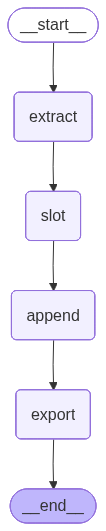

In [42]:
# Graph 조립
workflow = StateGraph(MetrologyState)
workflow.add_node('extract', extract_node)
workflow.add_node('slot', slot_node)
workflow.add_node('append', append_node)
workflow.add_node('export', export_node)

workflow.add_edge(START, 'extract')
workflow.add_edge('extract', 'slot')
workflow.add_edge('slot', 'append')
workflow.add_edge('append', 'export')
workflow.add_edge('export', END)

metrology_app = workflow.compile()
print('Graph compile OK')
metrology_app

## 6. 입력: 폴더 경로 / 이미지 URL / 다중 업로드

아래 중 **하나만** 사용하면 됩니다.

| 방법 | 입력 | 동작 |
|------|------|------|
| **A. 폴더 경로** | `C:/.../my_folder` | 폴더 안 이미지 **전부** 처리 |
| **A. 파일 경로** | `.../img.png` | 해당 파일 1장 |
| **A. 이미지 URL** | `https://.../img.png` | 다운로드 후 1장 |
| **B. 업로드** | 위젯에서 여러 장 선택 | `uploads/`에 저장 후 전부 처리 |

같은 패턴 이미지라고 가정하고, 첫 장을 기준으로 앵커 정렬 → Long 테이블 → 통계량을 만듭니다.


In [43]:
import re
import uuid
from urllib.parse import urlparse

import requests
from IPython.display import Image, display

UPLOAD_DIR = METROLOGY_DIR / 'uploads'
UPLOAD_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = METROLOGY_DIR / 'output'
OUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp', '.webp'}
_URL_RE = re.compile(r'^https?://', re.IGNORECASE)


def _safe_name(name: str) -> str:
    name = Path(name).name
    return re.sub(r'[^\w.\-]+', '_', name) or f'image_{uuid.uuid4().hex[:8]}.png'


def resolve_from_path(path: str | Path) -> Path:
    p = Path(path)
    if not p.exists():
        raise FileNotFoundError(f'파일/폴더 없음: {p}')
    return p.resolve()


def resolve_from_url(url: str, *, timeout: int = 30) -> Path:
    if not _URL_RE.match(url.strip()):
        raise ValueError(f'URL이 아닙니다: {url}')
    parsed = urlparse(url)
    fname = _safe_name(Path(parsed.path).name or 'download.png')
    if not Path(fname).suffix:
        fname += '.png'
    out = UPLOAD_DIR / f'{uuid.uuid4().hex[:8]}_{fname}'
    resp = requests.get(url, timeout=timeout)
    resp.raise_for_status()
    out.write_bytes(resp.content)
    print('downloaded →', out.name)
    return out.resolve()


def resolve_from_bytes(data: bytes, filename: str = 'upload.png') -> Path:
    fname = _safe_name(filename)
    out = UPLOAD_DIR / f'{uuid.uuid4().hex[:8]}_{fname}'
    out.write_bytes(data)
    return out.resolve()


def list_images_in_folder(folder: str | Path, *, recursive: bool = False) -> list[Path]:
    """폴더 안 이미지 경로 목록 (이름순)"""
    folder = Path(folder)
    if not folder.is_dir():
        raise NotADirectoryError(folder)
    pattern = '**/*' if recursive else '*'
    paths = [
        p.resolve()
        for p in sorted(folder.glob(pattern))
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]
    return paths


def collect_image_paths(
    source: str | Path,
    *,
    recursive: bool = False,
) -> list[Path]:
    """
    폴더 경로 / 파일 경로 / 이미지 URL → 처리할 Path 리스트
    """
    text = str(source).strip().strip('"').strip("'")
    if not text:
        raise ValueError('입력이 비어 있습니다')

    if _URL_RE.match(text):
        return [resolve_from_url(text)]

    p = resolve_from_path(text)
    if p.is_dir():
        paths = list_images_in_folder(p, recursive=recursive)
        if not paths:
            raise FileNotFoundError(f'폴더에 이미지가 없습니다: {p}')
        return paths
    if p.suffix.lower() not in IMAGE_EXTS:
        raise ValueError(f'이미지 확장자가 아닙니다: {p.suffix}')
    return [p]


def run_metrology_batch(
    image_paths: list[str | Path],
    *,
    align_threshold: float = 0.08,
) -> tuple[dict, 'pd.DataFrame']:
    """여러 이미지를 순차 처리하며 table_rows / reference_slots 누적"""
    table_rows: list[dict] = []
    reference_slots: list[dict] = []
    last_state: dict = {}

    for i, path in enumerate(image_paths):
        print(f'\n===== [{i+1}/{len(image_paths)}] {Path(path).name} =====')
        init = MetrologyState(
            image_path=str(path),
            table_rows=table_rows,
            reference_slots=reference_slots,
            align_threshold=align_threshold,
        )
        last_state = metrology_app.invoke(init)
        table_rows = list(last_state['table_rows'])
        reference_slots = list(last_state['reference_slots'])

    return last_state, rows_to_dataframe(table_rows)


def summarize_by_slot(
    df: 'pd.DataFrame',
    *,
    drop_unmatched: bool = True,
    min_count: int = 1,
) -> 'pd.DataFrame':
    if df is None or len(df) == 0:
        return pd.DataFrame()

    work = df.copy()
    if drop_unmatched:
        work = work[~work['slot_key'].astype(str).str.startswith('unmatched_')]
    if len(work) == 0:
        return pd.DataFrame()

    grouped = work.groupby(['slot_key', 'unit', 'orientation'], dropna=False)
    stats = grouped['value'].agg(
        n='count', mean='mean', std='std',
        min='min', median='median', max='max',
    ).reset_index()
    stats['std'] = stats['std'].fillna(0.0)
    stats['cv_pct'] = stats.apply(
        lambda r: (r['std'] / r['mean'] * 100) if r['mean'] else None,
        axis=1,
    )
    stats = stats[stats['n'] >= min_count].reset_index(drop=True)
    for col in ['mean', 'std', 'min', 'median', 'max', 'cv_pct']:
        stats[col] = stats[col].round(3)

    anchors = grouped[['anchor_x', 'anchor_y']].mean().reset_index()
    anchors['anchor_x'] = anchors['anchor_x'].round(3)
    anchors['anchor_y'] = anchors['anchor_y'].round(3)
    stats = stats.merge(anchors, on=['slot_key', 'unit', 'orientation'], how='left')
    return stats.sort_values(['orientation', 'slot_key']).reset_index(drop=True)


def pivot_values_by_image(df: 'pd.DataFrame', *, drop_unmatched: bool = True) -> 'pd.DataFrame':
    if df is None or len(df) == 0:
        return pd.DataFrame()
    work = df.copy()
    if drop_unmatched:
        work = work[~work['slot_key'].astype(str).str.startswith('unmatched_')]
    pivot = (
        work.pivot_table(
            index=['slot_key', 'unit', 'orientation'],
            columns='image_name',
            values='value',
            aggfunc='mean',
        )
        .reset_index()
    )
    pivot.columns.name = None
    return pivot


def save_results(df_long, df_stats=None, df_pivot=None):
    out_long = OUT_DIR / 'metrology_long.csv'
    df_long.to_csv(out_long, index=False, encoding='utf-8-sig')
    print('saved long :', out_long)
    if df_stats is not None and len(df_stats):
        out_stats = OUT_DIR / 'metrology_stats.csv'
        df_stats.to_csv(out_stats, index=False, encoding='utf-8-sig')
        print('saved stats:', out_stats)
    if df_pivot is not None and len(df_pivot):
        out_pivot = OUT_DIR / 'metrology_pivot.csv'
        df_pivot.to_csv(out_pivot, index=False, encoding='utf-8-sig')
        print('saved pivot:', out_pivot)


def run_from_source(source: str | Path, *, recursive: bool = False, align_threshold: float = 0.08):
    """폴더/파일/URL → 배치 실행 → (df_long, df_stats, df_pivot)"""
    paths = collect_image_paths(source, recursive=recursive)
    print(f'처리할 이미지 {len(paths)}장:')
    for p in paths:
        print(' -', p.name)

    state, df_long = run_metrology_batch(paths, align_threshold=align_threshold)
    df_stats = summarize_by_slot(df_long)
    df_pivot = pivot_values_by_image(df_long)
    save_results(df_long, df_stats, df_pivot)
    print('\n', state.get('summary', ''))
    return df_long, df_stats, df_pivot


print('UPLOAD_DIR:', UPLOAD_DIR.resolve())
print('OUT_DIR   :', OUT_DIR.resolve())
print('입력/배치/통계 함수 준비 완료')


UPLOAD_DIR: C:\Users\Admin\Desktop\실습폴더\data\metrology\uploads
OUT_DIR   : C:\Users\Admin\Desktop\실습폴더\data\metrology\output
입력/배치/통계 함수 준비 완료


### 방법 A — 폴더 경로 / 파일 / 이미지 URL

`INPUT_SOURCE`에 아래 중 하나를 넣고 실행하세요.

```python
INPUT_SOURCE = r'C:\Users\...\my_tem_folder'   # 폴더 → 안의 모든 이미지
INPUT_SOURCE = r'data/metrology'                   # 상대 경로 폴더도 OK
INPUT_SOURCE = r'data/metrology/tem_sample_01.png' # 파일 1장
INPUT_SOURCE = 'https://example.com/tem.png'       # 이미지 URL 1장
```


In [44]:
# ===== 여기를 수정 =====
INPUT_SOURCE = r'data/metrology'   # 폴더 / 파일 / URL
RECURSIVE = False                  # 하위 폴더까지 포함하려면 True
ALIGN_THRESHOLD = 0.08             # 앵커 매칭 거리 (작을수록 엄격)
# ========================

df_long, df_stats, df_pivot = run_from_source(
    INPUT_SOURCE,
    recursive=RECURSIVE,
    align_threshold=ALIGN_THRESHOLD,
)

print('\n=== Long 테이블 (측정값) ===')
display(df_long)

print('\n=== 슬롯별 통계 ===')
display(df_stats)

print('\n=== 슬롯 × 이미지 ===')
display(df_pivot)


처리할 이미지 1장:
 - tem_sample_01.png

===== [1/1] tem_sample_01.png =====
[extract] tem_sample_01.png: 6개 측정값
[slot] 내부 slot_key 부여: ['v_0.50_0.15', 'h_0.50_0.25', 'h_0.50_0.50', 'h_0.50_0.75', 'a_0.65_0.50', 'v_0.50_0.85']
[append] 기준 슬롯 6개 등록
[export] 이미지 1장 · 측정 6건
saved long : c:\Users\Admin\Desktop\실습폴더\data\metrology\output\metrology_long.csv
saved stats: c:\Users\Admin\Desktop\실습폴더\data\metrology\output\metrology_stats.csv
saved pivot: c:\Users\Admin\Desktop\실습폴더\data\metrology\output\metrology_pivot.csv

 이미지 1장 · 측정 6건

=== Long 테이블 (측정값) ===


,image_path,image_name,slot_key,value,unit,anchor_x,anchor_y,orientation,region
0,C:\Users\Admin\Desktop\실습폴더\data\metrology\tem...,tem_sample_01.png,v_0.50_0.15,34.3,nm,0.50,0.15,vertical,top
1,C:\Users\Admin\Desktop\실습폴더\data\metrology\tem...,tem_sample_01.png,h_0.50_0.25,25.9,nm,0.50,0.25,horizontal,top
2,C:\Users\Admin\Desktop\실습폴더\data\metrology\tem...,tem_sample_01.png,h_0.50_0.50,25.8,nm,0.50,0.50,horizontal,middle
3,C:\Users\Admin\Desktop\실습폴더\data\metrology\tem...,tem_sample_01.png,h_0.50_0.75,30.5,nm,0.50,0.75,horizontal,bottom
4,C:\Users\Admin\Desktop\실습폴더\data\metrology\tem...,tem_sample_01.png,a_0.65_0.50,77.9,°,0.65,0.50,angle,middle
5,C:\Users\Admin\Desktop\실습폴더\data\metrology\tem...,tem_sample_01.png,v_0.50_0.85,57.3,nm,0.50,0.85,vertical,bottom



=== 슬롯별 통계 ===


,slot_key,unit,orientation,n,mean,std,min,median,max,cv_pct,anchor_x,anchor_y
0,a_0.65_0.50,°,angle,1,77.9,0.0,77.9,77.9,77.9,0.0,0.65,0.50
1,h_0.50_0.25,nm,horizontal,1,25.9,0.0,25.9,25.9,25.9,0.0,0.50,0.25
2,h_0.50_0.50,nm,horizontal,1,25.8,0.0,25.8,25.8,25.8,0.0,0.50,0.50
3,h_0.50_0.75,nm,horizontal,1,30.5,0.0,30.5,30.5,30.5,0.0,0.50,0.75
4,v_0.50_0.15,nm,vertical,1,34.3,0.0,34.3,34.3,34.3,0.0,0.50,0.15
5,v_0.50_0.85,nm,vertical,1,57.3,0.0,57.3,57.3,57.3,0.0,0.50,0.85



=== 슬롯 × 이미지 ===


,slot_key,unit,orientation,tem_sample_01.png
0,a_0.65_0.50,°,angle,77.9
1,h_0.50_0.25,nm,horizontal,25.9
2,h_0.50_0.50,nm,horizontal,25.8
3,h_0.50_0.75,nm,horizontal,30.5
4,v_0.50_0.15,nm,vertical,34.3
5,v_0.50_0.85,nm,vertical,57.3


### 방법 B — 여러 장 파일 업로드

1. 아래 셀 실행 → 파일 선택 (여러 장 가능)  
2. 그다음 셀 실행 → 저장 후 전체 측정 + 통계


In [33]:
import ipywidgets as widgets

upload_widget = widgets.FileUpload(
    accept='image/*',
    multiple=True,
    description='이미지 선택',
)
upload_widget


FileUpload(value=(), accept='image/*', description='이미지 선택', multiple=True)

In [35]:
def _iter_uploads(widget):
    """ipywidgets 버전별 FileUpload value → (filename, bytes) 목록"""
    value = widget.value
    if not value:
        return []

    items = []
    if isinstance(value, dict):
        for key, meta in value.items():
            if isinstance(meta, dict):
                fname = meta.get('name', key)
                data = meta['content']
            else:
                fname = getattr(meta, 'name', key)
                data = getattr(meta, 'content', None)
                if data is None and hasattr(meta, 'tobytes'):
                    data = meta.tobytes()
            items.append((str(fname), bytes(data)))
    else:
        for meta in value:
            fname = getattr(meta, 'name', 'upload.png')
            data = getattr(meta, 'content', None)
            if data is None and hasattr(meta, 'tobytes'):
                data = meta.tobytes()
            items.append((str(fname), bytes(data)))
    return items


uploads = _iter_uploads(upload_widget)
if not uploads:
    print('업로드된 파일이 없습니다. 위 위젯에서 이미지를 선택한 뒤 다시 실행하세요.')
else:
    paths = [resolve_from_bytes(data, filename=fname) for fname, data in uploads]
    print(f'업로드 {len(paths)}장:')
    for p in paths:
        print(' -', p.name)

    state, df_long = run_metrology_batch(paths)
    df_stats = summarize_by_slot(df_long)
    df_pivot = pivot_values_by_image(df_long)
    save_results(df_long, df_stats, df_pivot)

    print('\n=== Long 테이블 ===')
    display(df_long)
    print('\n=== 통계 ===')
    display(df_stats)
    print('\n=== 슬롯 × 이미지 ===')
    display(df_pivot)


업로드 1장:
 - 66dd0ebd_tem_sample_01.png

===== [1/1] 66dd0ebd_tem_sample_01.png =====
[extract] 66dd0ebd_tem_sample_01.png: 6개 측정값
[slot] 내부 slot_key 부여: ['v_0.50_0.15', 'h_0.50_0.20', 'h_0.50_0.35', 'h_0.50_0.60', 'a_0.60_0.50', 'v_0.50_0.80']
[append] 기준 슬롯 6개 등록
[export] 이미지 1장 · 측정 6건
saved long : c:\Users\Admin\Desktop\실습폴더\data\metrology\output\metrology_long.csv
saved stats: c:\Users\Admin\Desktop\실습폴더\data\metrology\output\metrology_stats.csv
saved pivot: c:\Users\Admin\Desktop\실습폴더\data\metrology\output\metrology_pivot.csv

=== Long 테이블 ===


,image_path,image_name,slot_key,value,unit,anchor_x,anchor_y,orientation,region
0,C:\Users\Admin\Desktop\실습폴더\data\metrology\upl...,66dd0ebd_tem_sample_01.png,v_0.50_0.15,34.3,nm,0.5,0.15,vertical,top
1,C:\Users\Admin\Desktop\실습폴더\data\metrology\upl...,66dd0ebd_tem_sample_01.png,h_0.50_0.20,25.9,nm,0.5,0.20,horizontal,top
2,C:\Users\Admin\Desktop\실습폴더\data\metrology\upl...,66dd0ebd_tem_sample_01.png,h_0.50_0.35,25.8,nm,0.5,0.35,horizontal,middle
3,C:\Users\Admin\Desktop\실습폴더\data\metrology\upl...,66dd0ebd_tem_sample_01.png,h_0.50_0.60,30.5,nm,0.5,0.60,horizontal,bottom
4,C:\Users\Admin\Desktop\실습폴더\data\metrology\upl...,66dd0ebd_tem_sample_01.png,a_0.60_0.50,77.9,°,0.6,0.50,angle,middle
5,C:\Users\Admin\Desktop\실습폴더\data\metrology\upl...,66dd0ebd_tem_sample_01.png,v_0.50_0.80,57.3,nm,0.5,0.80,vertical,bottom



=== 통계 ===


,slot_key,unit,orientation,n,mean,std,min,median,max,cv_pct,anchor_x,anchor_y
0,a_0.60_0.50,°,angle,1,77.9,0.0,77.9,77.9,77.9,0.0,0.6,0.50
1,h_0.50_0.20,nm,horizontal,1,25.9,0.0,25.9,25.9,25.9,0.0,0.5,0.20
2,h_0.50_0.35,nm,horizontal,1,25.8,0.0,25.8,25.8,25.8,0.0,0.5,0.35
3,h_0.50_0.60,nm,horizontal,1,30.5,0.0,30.5,30.5,30.5,0.0,0.5,0.60
4,v_0.50_0.15,nm,vertical,1,34.3,0.0,34.3,34.3,34.3,0.0,0.5,0.15
5,v_0.50_0.80,nm,vertical,1,57.3,0.0,57.3,57.3,57.3,0.0,0.5,0.80



=== 슬롯 × 이미지 ===


,slot_key,unit,orientation,66dd0ebd_tem_sample_01.png
0,a_0.60_0.50,°,angle,77.9
1,h_0.50_0.20,nm,horizontal,25.9
2,h_0.50_0.35,nm,horizontal,25.8
3,h_0.50_0.60,nm,horizontal,30.5
4,v_0.50_0.15,nm,vertical,34.3
5,v_0.50_0.80,nm,vertical,57.3


## 사용 요약

```python
# 폴더 안 모든 이미지
df_long, df_stats, df_pivot = run_from_source(r'C:\path\to\folder')

# 단일 파일 / URL
df_long, df_stats, df_pivot = run_from_source(r'data/metrology/a.png')
df_long, df_stats, df_pivot = run_from_source('https://.../a.png')

# 업로드는 위젯 사용 (방법 B)
```

결과는 `data/metrology/output/` 에 저장됩니다.

| 파일 | 내용 |
|------|------|
| `metrology_long.csv` | 이미지별 측정값 (Long) |
| `metrology_stats.csv` | 슬롯별 n/mean/std/... |
| `metrology_pivot.csv` | 슬롯 × 이미지 원본값 |

**참고:** 웹 폴더 URL(디렉터리 리스팅)은 지원하지 않습니다. 로컬 폴더 경로를 쓰거나, 이미지를 업로드하세요.


# 오늘 변경사항 요약 (2026-07-13)

`AIagent_practice.ipynb` 중심으로 **기획 → 구현 → 입력 UX → edge 측정 분리**까지 진행했습니다.

---

## 1. Agent 구현 (Phase 1)

기획서만 있던 노트북에 실행 코드를 섹션별로 추가했습니다.

| 구성 | 내용 |
|------|------|
| State / Graph | extract → slot → append → export |
| VLM overlay | 숫자·단위·앵커 추출 (`measure_mode='overlay'`) |
| 슬롯 | 앵커+방향으로 `slot_key` 부여, 여러 장 정렬 |
| 통계 | `summarize_by_slot`, `pivot_values_by_image` |
| 저장 | `data/metrology/output/*.csv` |

---

## 2. 입력 방식 정리

데모 셀은 제거하고, **실사용 입력**만 남겼습니다.

| 입력 | 동작 |
|------|------|
| 폴더 경로 | 안 이미지 전부 처리 |
| 파일 / 이미지 URL | 1장 처리 |
| **`.zip` / zip URL** | 해제 후 이미지 전부 |
| 위젯 업로드 | 여러 장 또는 zip |

핵심 함수: `collect_image_paths`, `run_from_source`

---

## 3. SEM Edge 측정 Tool

오버레이 숫자 없이 **edge로 재는 경로**를 추가했습니다.

| 항목 | 내용 |
|------|------|
| 모드 | `edge` (기본) / `overlay` / `auto` |
| 측정 | height, top/mid/bot width (12%/50%/88%), sidewall angle |
| 스케일 | `NM_PER_PIXEL` (없으면 `px`) |
| 파일 | **`sem_edge_tool.py`** (노트북과 같은 폴더로 분리) |

노트북 §5.5는 `from sem_edge_tool import measure_sem_structure` 만 합니다.

---

## 4. 산출물 위치

```
실습폴더/
├── AIagent_practice.ipynb   # Agent + 입력/배치 UX
├── sem_edge_tool.py         # edge 측정 (분리)
└── data/metrology/
    ├── tem_sample_01.png
    ├── uploads/             # 다운로드·zip 해제
    └── output/              # CSV, edge overlay
```

---

## 5. 아직 남은 점

- 스케일바 **자동** 인식 없음 → `NM_PER_PIXEL` 수동
- edge는 **기둥형 단면 + 고정 비율** 휴리스틱
- `.rar` / `.7z`, 웹 폴더 URL 미지원
- GitHub push는 오늘 대화에서 **요청·실행하지 않음** (로컬 변경)

---

**한 줄:** TEM/SEM 이미지를 폴더·zip·업로드로 넣고, overlay(VLM) 또는 edge(CV)로 측정값을 Long 테이블·통계로 뽑는 Agent 뼈대를 만들었고, edge tool만 `sem_edge_tool.py`로 분리했습니다.